# Lab 3: Operacje punktowe i Arytmetyka Obrazów

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from skimage import exposure # Nowa biblioteka do przetwarzania obrazów

plt.rcParams['figure.figsize'] = (12, 6)

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


## 1. Arytmetyka Obrazów: Cyfrowa Angiografia Subtrakcyjna (DSA)
DSA to technika radiologiczna służąca do precyzyjnego uwidaczniania naczyń krwionośnych. Wykonuje się dwa zdjęcia (najczęściej RTG lub fluoroskopia):
1. **Maska (Mask image):** Zdjęcie pacjenta przed podaniem kontrastu (widać kości, tkanki).
2. **Live (Contrast image):** Zdjęcie w momencie przepływu kontrastu jodowego przez naczynia.

Odejmując jedno od drugiego, usuwamy tło (kości, mięśnie), zostawiając sam zarys naczyń krwionośnych.

In [9]:
# --- GENEROWANIE SYNTETYCZNYCH DANYCH DSA ---
size = 256
x, y = np.meshgrid(np.linspace(-1, 1, size), np.linspace(-1, 1, size))

# Tworzymy "Ciało pacjenta" (Maska)
background = np.exp(-(x**2 + y**2) * 2) * 100 # Tło tkanek
bone = np.exp(-((x-0.3)**2 + y**2 * 10)) * 80 # Kość
noise = np.random.normal(0, 3, (size, size)) # Szum kwantowy
img_mask = background + bone + noise

# Tworzymy "Live" (Maska + Naczynia z kontrastem)
img_live = img_mask.copy()
vessels = np.zeros((size, size))
vessels[50:200, 120:128] = 60 # Tętnica główna
vessels[100:115, 128:180] = 50 # Odgałęzienie
img_live += vessels

print("Dane syntetyczne wygenerowane!")

Dane syntetyczne wygenerowane!


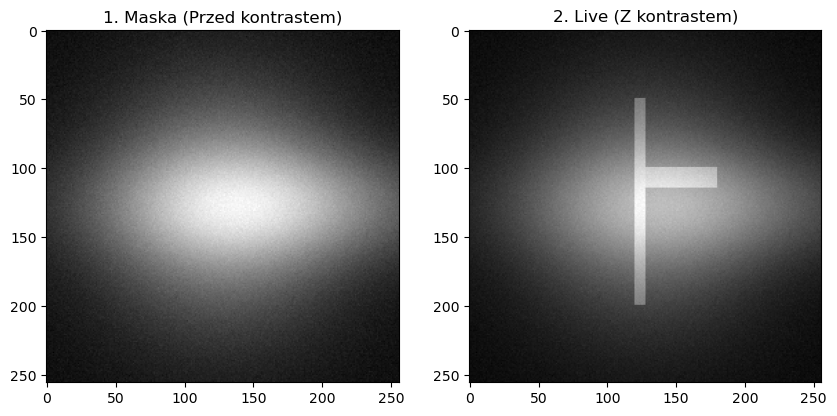

In [10]:
# Wizualizacja przed subtrakcją
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_mask, cmap='gray')
axes[0].set_title('1. Maska (Przed kontrastem)')
axes[1].imshow(img_live, cmap='gray')
axes[1].set_title('2. Live (Z kontrastem)')
plt.show()

### Zadanie 1: Wykonaj subtrakcję
1. Stwórz zmienną `img_dsa`, która będzie wynikiem odejmowania maski od obrazu z kontrastem.
2. Wyświetl wynik. Skomentuj, co udało się wyizolować.

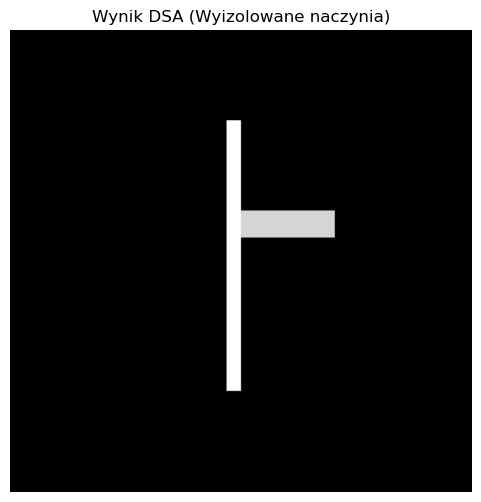

In [12]:
# Miejsce na Twój kod (Zadanie 1):
# 1. Wykonanie subtrakcji (Obraz z kontrastem minus Maska)
img_dsa = img_live - img_mask

# (Opcjonalnie) Dobrą praktyką jest usunięcie wartości ujemnych, 
# które mogą powstać w wyniku odejmowania zaszumionych pikseli tła:
img_dsa = np.clip(img_dsa, 0, None)

# 2. Wizualizacja wyniku
plt.figure(figsize=(6, 6))
plt.imshow(img_dsa, cmap='gray')
plt.title('Wynik DSA (Wyizolowane naczynia)')
plt.axis('off')
plt.show()

## 2. Globalne Wyrównywanie Histogramu (HE)
Problem z obrazami medycznymi polega często na niskim kontraście. Klasycznym algorytmem informatycznym do rozwiązywania tego problemu jest Wyrównywanie Histogramu (Histogram Equalization), które stara się "rozciągnąć" jasności pikseli tak, aby wykorzystać pełną skalę.

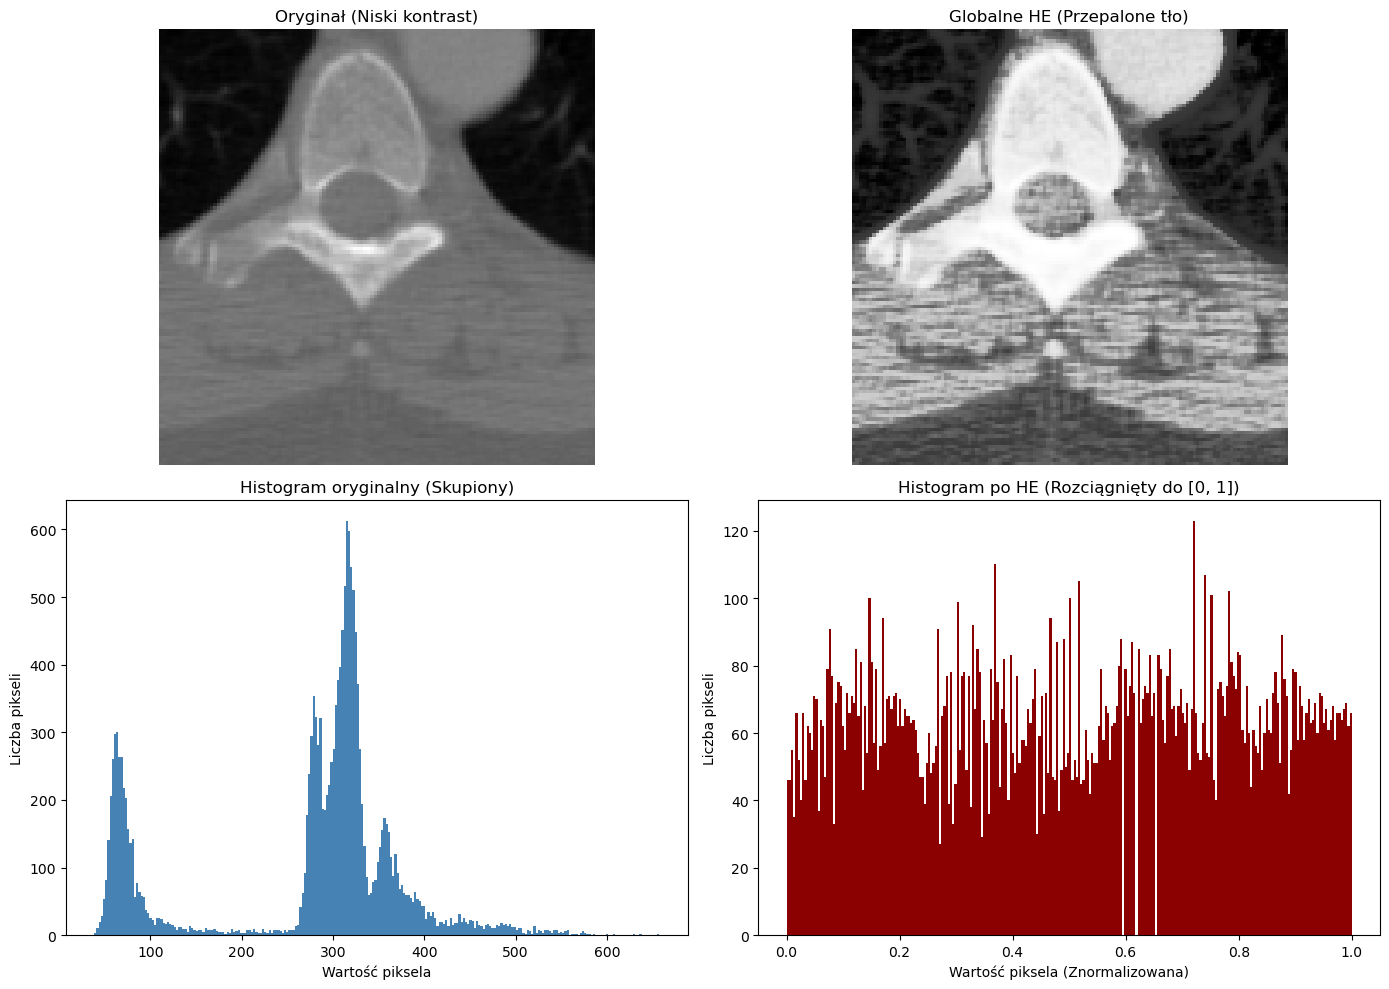

In [16]:
# Wczytanie obrazu CT i celowe sztuczne zmniejszenie jego kontrastu do celów ćwiczenia
from pydicom.data import get_testdata_files
ds = pydicom.dcmread(get_testdata_files("CT_small.dcm")[0])
#ds = pydicom.dcmread(get_testdata_files("MR_small.dcm")[0]) #rezonans magnetyczny
#ds = pydicom.dcmread(get_testdata_files("JPEG2000.dcm")[0]) #rentgen
ct_image = ds.pixel_array

# Sztuczna degradacja kontrastu (symulacja niedoświetlonego zdjęcia RTG)
low_contrast_img = (ct_image * 0.3).astype(np.float64)

# Zastosowanie globalnego HE z biblioteki skimage
# Uwaga: funkcja equalize_hist zwraca obraz znormalizowany do przedziału [0.0, 1.0]
img_he = exposure.equalize_hist(low_contrast_img)

# Przygotowanie siatki 2x2: wiersz 0 (obrazy), wiersz 1 (histogramy)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. ORYGINAŁ (Lewa kolumna)
axes[0, 0].imshow(low_contrast_img, cmap='gray')
axes[0, 0].set_title('Oryginał (Niski kontrast)')
axes[0, 0].axis('off')

# ravel() spłaszcza macierz 2D do 1D, co jest wymagane przez funkcję hist()
axes[1, 0].hist(low_contrast_img.ravel(), bins=256, color='steelblue')
axes[1, 0].set_title('Histogram oryginalny (Skupiony)')
axes[1, 0].set_xlabel('Wartość piksela')
axes[1, 0].set_ylabel('Liczba pikseli')

# 2. PO GLOBALNYM HE (Prawa kolumna)
axes[0, 1].imshow(img_he, cmap='gray')
axes[0, 1].set_title('Globalne HE (Przepalone tło)')
axes[0, 1].axis('off')

# Po HE wartości są w przedziale 0-1
axes[1, 1].hist(img_he.ravel(), bins=256, color='darkred')
axes[1, 1].set_title('Histogram po HE (Rozciągnięty do [0, 1])')
axes[1, 1].set_xlabel('Wartość piksela (Znormalizowana)')
axes[1, 1].set_ylabel('Liczba pikseli')

plt.tight_layout()
plt.show()

**Dlaczego to wygląda źle?**
Globalne HE wzmacnia kontrast wszędzie tak samo. W medycynie prowadzi to do:
1. Przepalenia (zbyt białych) lub niedoświetlenia ważnych struktur.
2. Dramatycznego uwydatnienia szumu radiologicznego w tłach.

## 3. CLAHE (Contrast Limited Adaptive Histogram Equalization)
Rozwiązaniem, które zrewolucjonizowało radiologię cyfrową, jest CLAHE. Algorytm ten:
- Działa **lokalnie** (adaptacyjnie) - dzieli obraz na małe kafelki i wyrównuje kontrast wewnątrz każdego z nich osobno.
- Ma **limit** (Contrast Limited) - ucina zbyt wysokie piki w histogramie, co zapobiega potęgowaniu szumu.

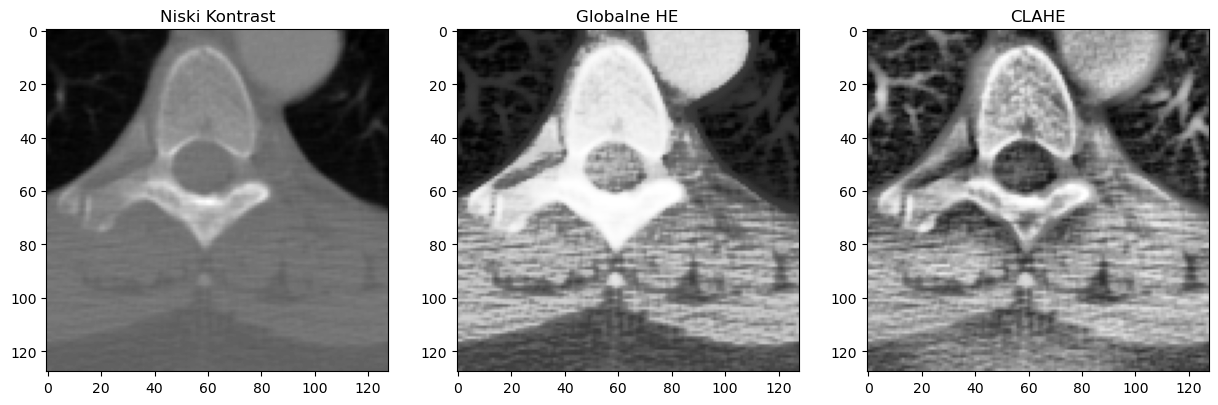

In [20]:
# 1. Normalizacja Min-Max do przedziału [0.0, 1.0]
img_min = np.min(low_contrast_img)
img_max = np.max(low_contrast_img)
low_contrast_norm = (low_contrast_img - img_min) / (img_max - img_min)

# 2. Zastosowanie CLAHE na znormalizowanym obrazie
img_clahe = exposure.equalize_adapthist(low_contrast_norm, clip_limit=0.03)

# 3. Wizualizacja (pozostaje bez zmian)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(low_contrast_norm, cmap='gray')
axes[0].set_title('Niski Kontrast')
axes[1].imshow(img_he, cmap='gray')
axes[1].set_title('Globalne HE')
axes[2].imshow(img_clahe, cmap='gray')
axes[2].set_title('CLAHE')
plt.show()

### Zadanie 2: Eksperymenty z filtrem CLAHE
Funkcja `exposure.equalize_adapthist()` przyjmuje dwa ważne argumenty:
- `clip_limit` (domyślnie 0.01): Wartość od 0 do 1. Im wyższa, tym silniejszy kontrast (ale więcej szumu).
- `kernel_size` (np. przypisanie krotki `(32, 32)`): Rozmiar lokalnego kafelka, w którym algorytm bada kontrast.

**Polecenie:**
Wygeneruj dwa nowe obrazy używając CLAHE na obrazie `low_contrast_img`:
1. Obraz ekstremalnie zaszumiony (bardzo wysoki `clip_limit`).
2. Obraz o bardzo płaskim, słabym kontraście, przypominający oryginał (bardzo niski `clip_limit`).
Wyświetl je obok siebie.

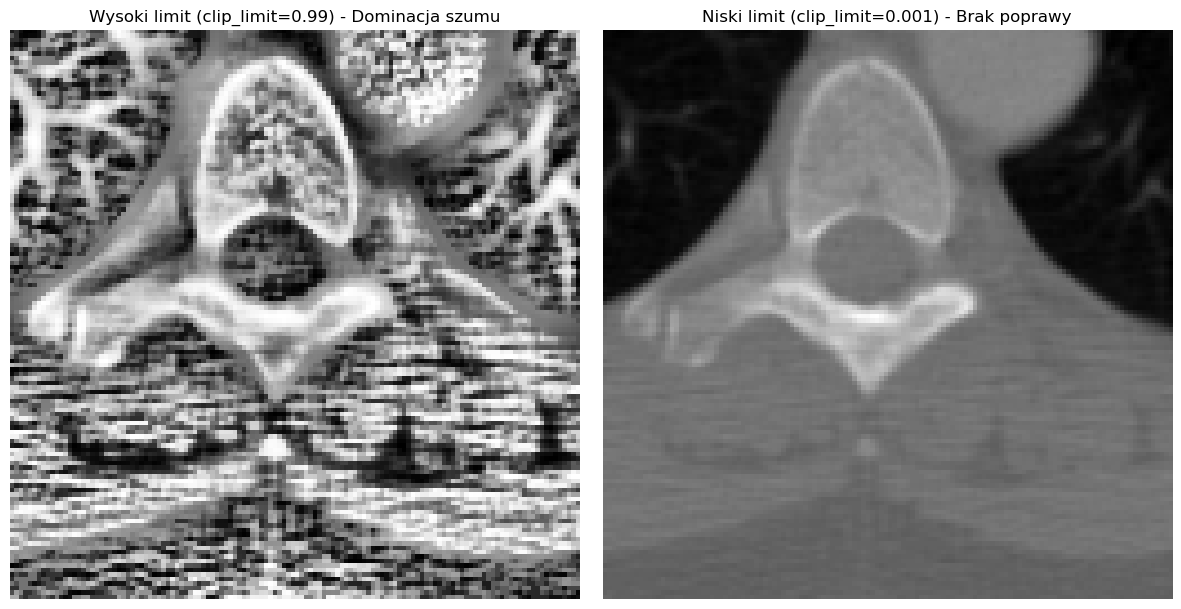

In [23]:
# Miejsce na Twój kod (Zadanie 2):
# 1. Obraz ekstremalnie zaszumiony (bardzo wysoki clip_limit)
clahe_high_noise = exposure.equalize_adapthist(low_contrast_norm, clip_limit=0.99)

# 2. Obraz o bardzo płaskim kontraście (bardzo niski clip_limit)
clahe_flat = exposure.equalize_adapthist(low_contrast_norm, clip_limit=0.001)

# 3. Wyświetlenie wyników obok siebie
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(clahe_high_noise, cmap='gray')
axes[0].set_title('Wysoki limit (clip_limit=0.99) - Dominacja szumu')
axes[0].axis('off')

axes[1].imshow(clahe_flat, cmap='gray')
axes[1].set_title('Niski limit (clip_limit=0.001) - Brak poprawy')
axes[1].axis('off')

plt.tight_layout()
plt.show()

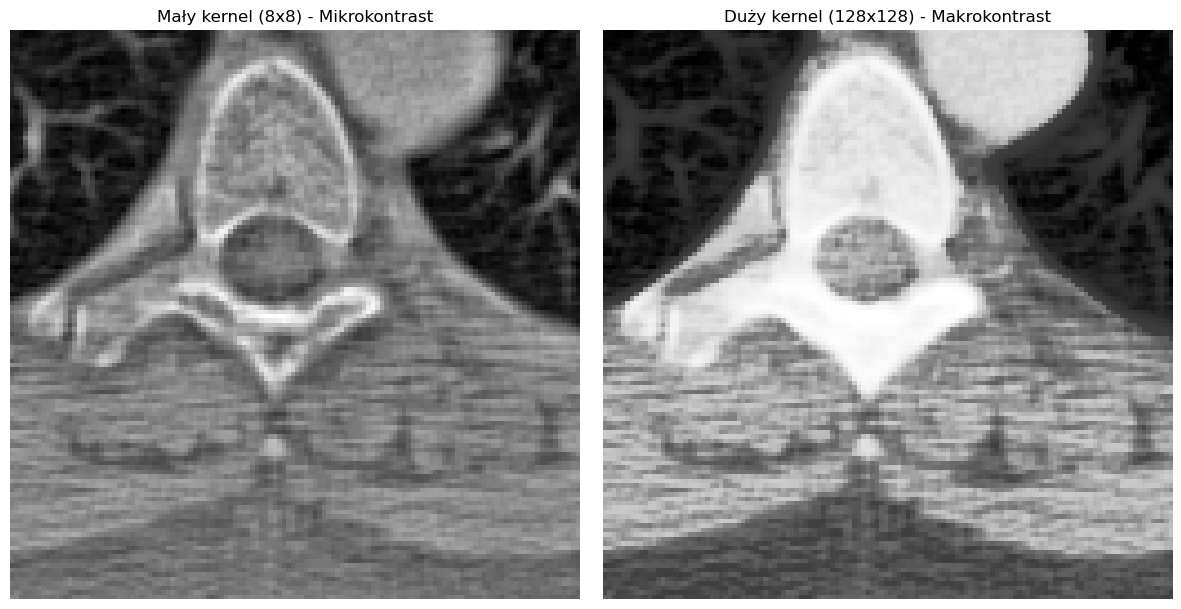

In [24]:
# 1. Bardzo małe okno lokalne (8x8 pikseli)
clahe_small = exposure.equalize_adapthist(low_contrast_norm, kernel_size=(8, 8), clip_limit=0.03)

# 2. Bardzo duże okno (np. 128x128 pikseli dla obrazu 256x256)
clahe_large = exposure.equalize_adapthist(low_contrast_norm, kernel_size=(128, 128), clip_limit=0.03)

# 3. Wyświetlenie wyników obok siebie
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(clahe_small, cmap='gray')
axes[0].set_title('Mały kernel (8x8) - Mikrokontrast')
axes[0].axis('off')

axes[1].imshow(clahe_large, cmap='gray')
axes[1].set_title('Duży kernel (128x128) - Makrokontrast')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### Zadanie 3: Zastosowanie mapy kolorów (LUT)
Ludzkie oko potrafi rozróżnić zaledwie kilkadziesiąt odcieni szarości, ale dostrzega miliony barw. W fizyce medycznej i radiologii (szczególnie w badaniach PET czy Doppler) wykorzystujemy ten fakt, stosując **pseudokolor**. 

Jest to klasyczna operacja punktowa. Zamiast mapować jasność na nową jasność (jak w algorytmach HE), mapujemy pojedynczą wartość szarości na konkretny kolor (RGB) ze zdefiniowanej tabeli (tzw. Lookup Table - LUT). 

Dzięki temu zabiegowi, drobne różnice w gęstości radiologicznej tkanek, które były niewidoczne w odcieniach szarości, nagle "wybuchają" kolorem, ułatwiając lekarzowi lokalizację np. ogniska zapalnego.

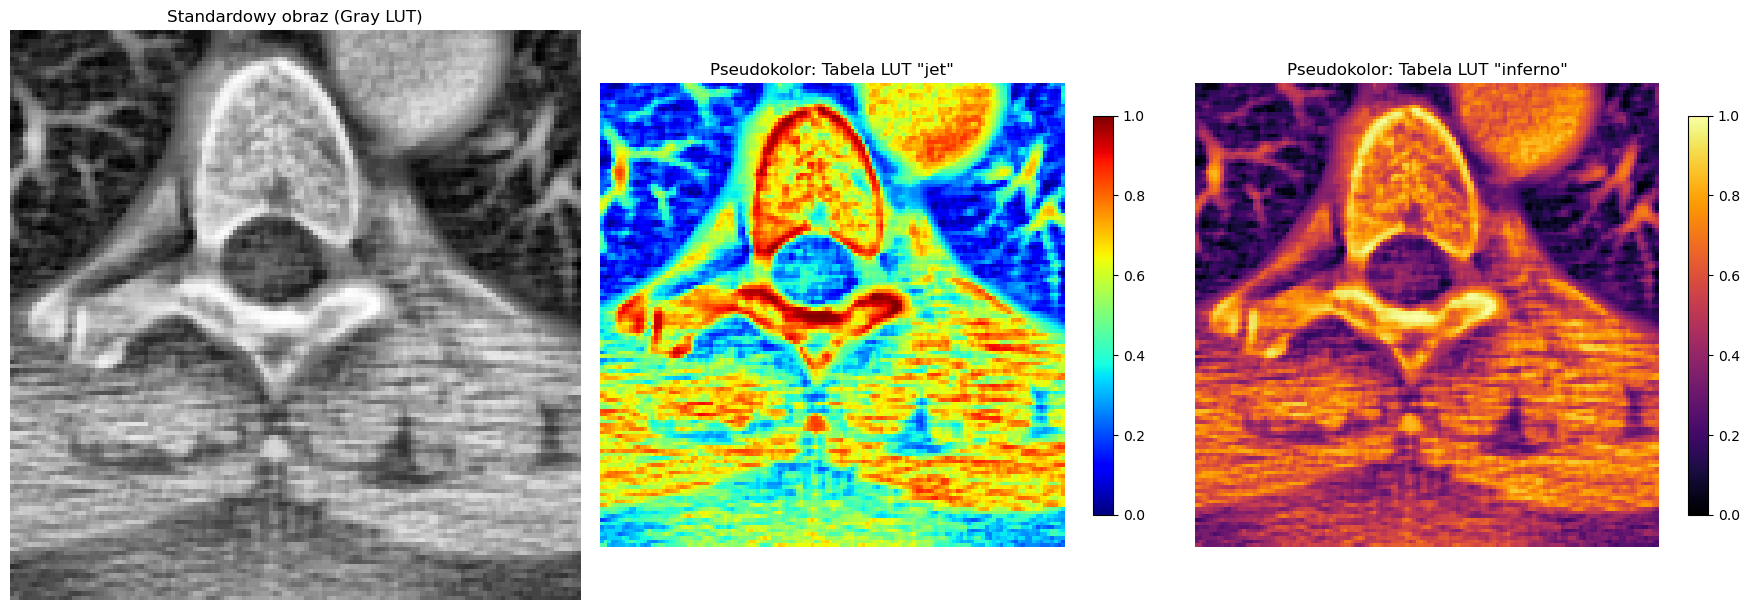

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Standardowy obraz w odcieniach szarości
axes[0].imshow(img_clahe, cmap='gray')
axes[0].set_title('Standardowy obraz (Gray LUT)')
axes[0].axis('off')

# 2. Mapa kolorów 'jet' - klasyk w fizyce i inżynierii
# Często używana do mapowania przepływów (Doppler) i naprężeń
im1 = axes[1].imshow(img_clahe, cmap='jet')
axes[1].set_title('Pseudokolor: Tabela LUT "jet"')
axes[1].axis('off')
# Dodanie paska legendy, aby pokazać mapowanie wartości na kolor
fig.colorbar(im1, ax=axes[1], shrink=0.7) 

# 3. Mapa 'inferno' - percepcynie jednolita
# Doskonała do PET i pokazywania "gorących punktów" (np. wychwyt znacznika)
im2 = axes[2].imshow(img_clahe, cmap='inferno')
axes[2].set_title('Pseudokolor: Tabela LUT "inferno"')
axes[2].axis('off')
fig.colorbar(im2, ax=axes[2], shrink=0.7)

plt.tight_layout()
plt.show()

In [32]:
# Pobranie pełnej listy dostępnych map kolorów
wszystkie_mapy = plt.colormaps()

# Wyświetlenie liczby wszystkich map
print(f"Dostępnych map: {len(wszystkie_mapy)}")

# Wyświetlenie przykładowych (np. pierwszych 20)
print(wszystkie_mapy[:20])

Dostępnych map: 170
['magma', 'inferno', 'plasma', 'viridis', 'cividis', 'twilight', 'twilight_shifted', 'turbo', 'Blues', 'BrBG', 'BuGn', 'BuPu', 'CMRmap', 'GnBu', 'Greens', 'Greys', 'OrRd', 'Oranges', 'PRGn', 'PiYG']


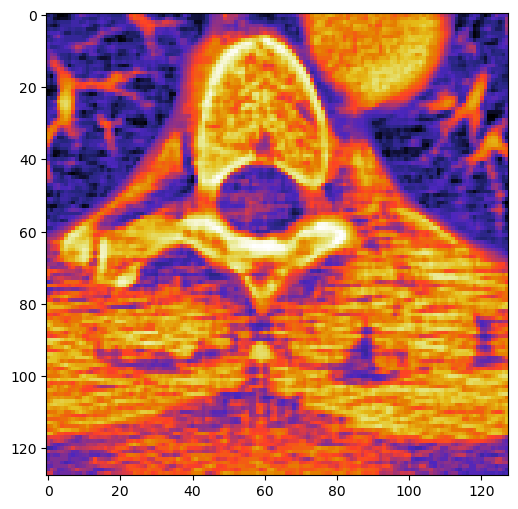

In [38]:
# miejsce na ekpserymenty z pseudokolorami
plt.imshow(img_clahe, cmap='CMRmap')